In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from clima_ecuador import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
R = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
def figura(nombre, ancho=950):
    display(Image(filename=str(config.FIGURAS / nombre), width=ancho))
def reporte(nombre):
    return pd.read_csv(config.REPORTES / nombre)

# 06 · ¿Cuánto se parece ERA5 a lo que miden las estaciones?

Comparo la celda de ERA5 de cada estación de **NOAA GHCN-Daily** en Ecuador (fuente independiente) con lo medido.
Las 8 estaciones con datos recientes cubren las 4 regiones. Limitaciones de la muestra: pocas estaciones (INAMHI no
publica sus series en un formato abierto descargable), huecos largos y la lluvia de Galápagos con solo 523 días.

In [2]:
from clima_ecuador import validacion
v = reporte("validacion_estaciones.csv")
v[["nombre", "region", "altitud", "desde", "hasta", "dias_tmax", "sesgo_tmax", "sesgo_tmin", "r_anom_tmax",
   "dias_precip", "ratio_lluvia", "r_lluvia_mensual", "dias_humedos_era5_pct", "dias_humedos_est_pct"]].round(2)

,nombre,region,altitud,desde,hasta,dias_tmax,sesgo_tmax,sesgo_tmin,r_anom_tmax,dias_precip,ratio_lluvia,r_lluvia_mensual,dias_humedos_era5_pct,dias_humedos_est_pct
0,San Cristóbal (Galápagos),Galápagos,19,1985,2024,2563,-5.110,0.870,0.710,523,0.260,NaN,11.850,26.580
1,La Concordia,Costa,360,2005,2024,2796,-1.490,0.130,0.390,2300,0.560,0.750,74.870,58.300
2,Izobamba (Quito),Sierra,3058,2005,2024,2592,-2.920,2.370,0.560,1720,1.590,0.560,97.620,67.150
3,Nuevo Rocafuerte,Amazonía,265,2005,2024,1933,-3.130,-0.150,0.540,1575,0.860,0.730,85.080,68.380
4,Portoviejo,Costa,60,2001,2024,1915,-2.220,1.660,0.540,729,1.490,NaN,66.800,47.050
5,Puyo,Amazonía,960,2011,2024,1791,-0.720,0.750,0.580,1677,0.490,0.400,84.850,76.980
6,Cañar,Sierra,3083,2001,2024,1628,-2.330,-0.200,0.430,1048,4.570,NaN,86.260,45.710
7,Loja La Argelia,Sierra,2160,2001,2024,2041,-0.670,1.320,0.400,1641,1.100,0.760,63.560,57.460


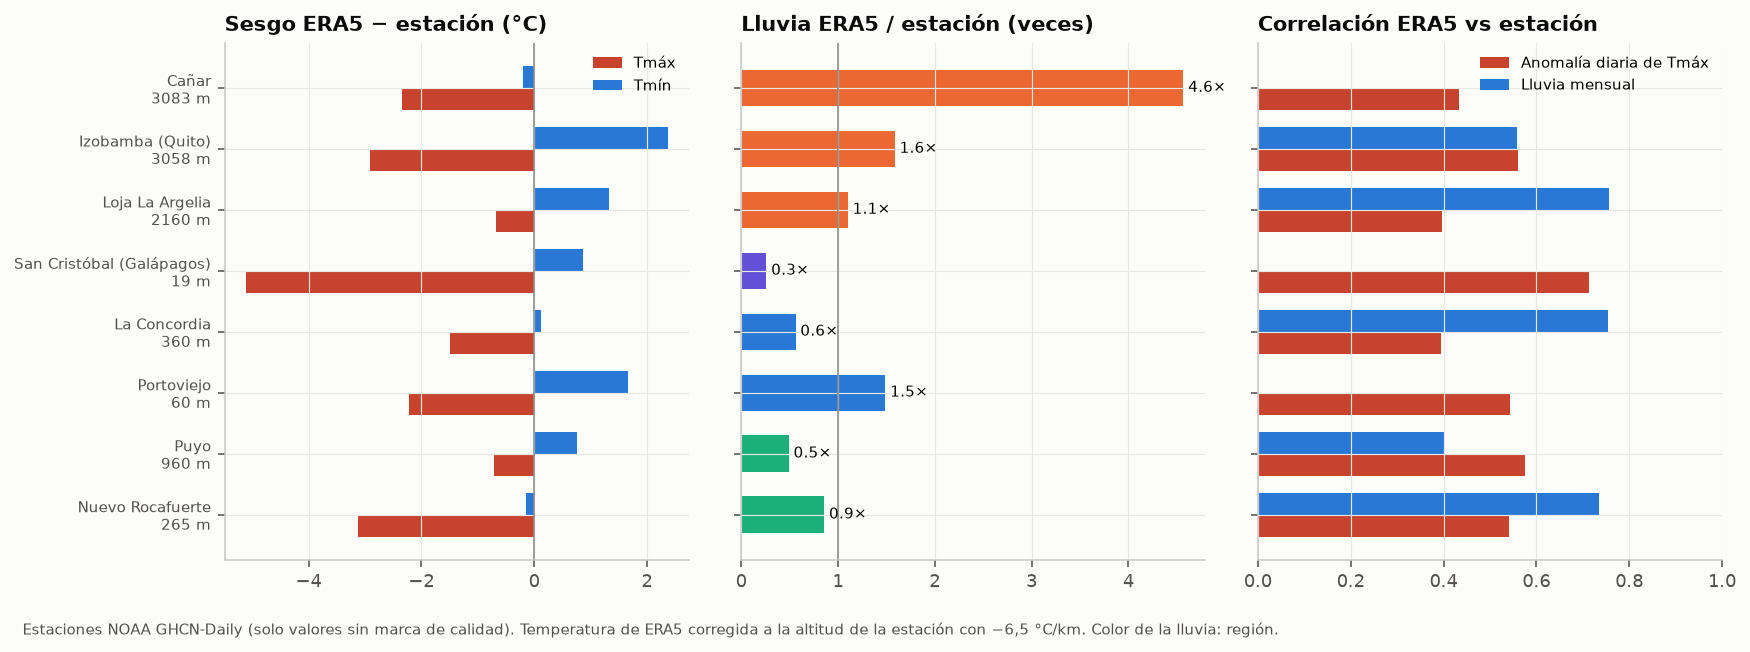

In [3]:
figura("14_validacion_estaciones.png")

**Temperatura**
* ERA5 subestima la **Tmáx en todas las estaciones** (−0,7 a −5,1 °C) y en la Sierra sobreestima la Tmín
  (Izobamba +2,4 °C): el reanálisis **aplana el ciclo diario**. Una celda de 25 km mezcla valles, laderas y páramo,
  y su suelo "promedio" no se calienta de día ni se enfría de noche como un punto concreto.
* **San Cristóbal (Galápagos): −5,1 °C en Tmáx**. La celda de ERA5 es mar: la temperatura de una celda oceánica
  sigue a la del agua, no a la del suelo de la isla.
* Las **anomalías diarias** sí se correlacionan (r = 0,39–0,71): ERA5 sigue razonablemente los días más cálidos o más fríos
  que lo normal, que es lo que importa para extremos relativos (la pendiente de largo plazo no se contrastó con estaciones).

**Lluvia**
* Errores de un factor 2 a 4 en ambos sentidos: **Cañar ×4,6, Izobamba ×1,6**, pero Puyo ×0,5 y La Concordia ×0,6.
* ERA5 **llueve demasiado seguido**: en Izobamba el 98 % de los días tiene ≥ 1 mm frente al 67 % medido. Es el
  conocido sesgo de "llovizna" de los modelos con convección parametrizada.
* La lluvia **mensual** sí se correlaciona (r = 0,40–0,76 donde hay datos): el reanálisis acierta qué meses son
  más lluviosos aunque falle en cuánto.

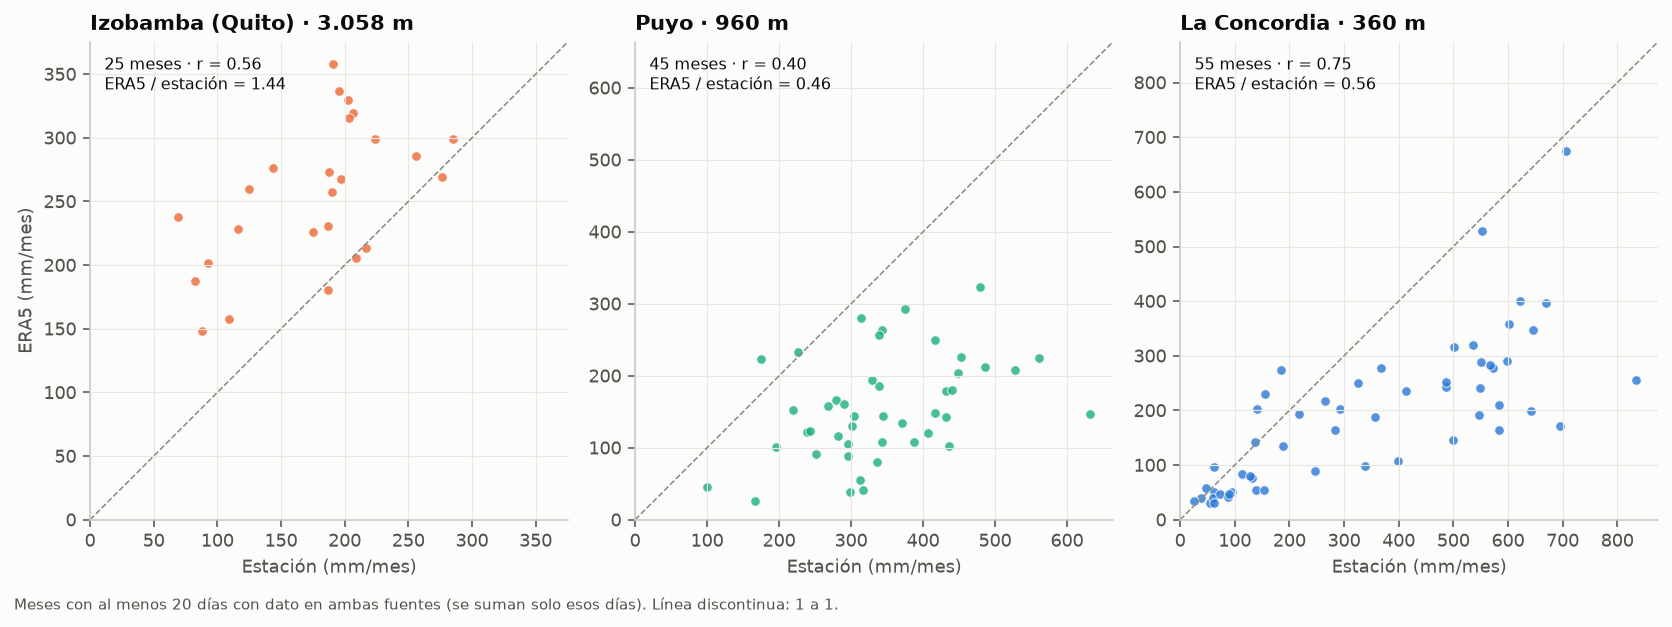

In [4]:
figura("15_validacion_lluvia_mensual.png")

## Conclusión: qué usar de ERA5 y qué no

| Uso | ¿Sirve ERA5 aquí? |
|---|---|
| Anomalías de **temperatura** | ✅ Sí: correlación de anomalías de 0,39 a 0,71 y sin saltos (Pettitt). Su pendiente de largo plazo no se contrastó con estaciones |
| Extremos de calor **relativos** a cada ciudad (TX90p, olas) | ✅ Sí, con umbrales propios de cada celda |
| Temperatura **absoluta** de una ciudad andina o de Galápagos | ⚠️ No: sesgos de 1 a 5 °C |
| **Totales** de lluvia en la Sierra y la Amazonía | ❌ No: errores de ×0,3 a ×4,6 |
| Días secos y rachas secas en los Andes | ❌ No: llueve casi todos los días en el modelo |
| Variabilidad **mensual** de la lluvia y respuesta a El Niño | ✅ Sí en la Costa (r = 0,76 en La Concordia) |

**Mejoras posibles:** usar ERA5-Land (0,1°) para temperatura, CHIRPS (5 km, combina satélite y estaciones) para lluvia,
o corregir el sesgo por cuantiles con las estaciones del INAMHI si se consiguen sus series.

In [5]:
unidas = validacion.unir_estaciones(pd.read_parquet(config.DIARIO), pd.read_parquet(config.ESTACIONES_DIARIO))
izobamba = unidas[unidas["estacion"] == "ECM00084088"].dropna(subset=["tmax_est"])
izobamba.assign(mes=izobamba["fecha"].dt.month).groupby("mes")[["tmax_era5", "tmax_est", "tmin_era5", "tmin_est"]].mean().round(1)

,tmax_era5,tmax_est,tmin_era5,tmin_est
mes,,,,
1,16.100,19.400,9.000,6.800
2,15.800,18.900,9.200,7.100
3,16.100,18.700,9.200,7.100
4,16.400,19.000,9.000,6.800
5,16.500,19.200,9.300,6.700
6,16.900,19.300,8.800,5.900
7,17.000,19.700,8.800,6.100
8,17.500,20.200,8.700,5.700
9,17.400,20.400,8.700,6.100
